# Stage 2: the corrected inference on the same 70 stars

Stage 1 unchanged except for the per-star marginal likelihood:

* `mw14`: Morton & Winn (2014) Eq. 13 = Masuda & Winn (2020) Eq. 18 (as published)
* `correct`: Masuda & Winn (2020) Eq. 9, i.e. Eq. 13 with the 1/sin i Jacobian restored

Primary result: all 70 stars, `v sin i` errors as published (f = 1). Alongside:
the global error-inflation ladder f ∈ {1.0, 1.15, 1.35}, and the 62-star
x ≤ +2σ cut, which suppresses signal by construction (Stage 1 §13) and is reported only
for completeness.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from src.data import load_mw14_table
from src.obliquity import log_kappa_prior
from src.hierarchical import (COSI_GRID, KAPPA_GRID, fcosi_table, run_sample,
    per_star_log_likelihood, kappa_posterior, summarize_kappa, permutation_test,
    inclination_upper_limit_deg, kl_divergence)

FIG, PROC = ROOT / "figures", ROOT / "data/processed"
METHODS = ("mw14", "correct")
LADDER = (1.0, 1.15, 1.35)
GCOL = {"single": "#2a78d6", "multi": "#eb6834"}
MLS = {"mw14": "--", "correct": "-"}
MLABEL = {"mw14": "MW14 Eq. 13 (as published)", "correct": "corrected (MW20 Eq. 9)"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

df = load_mw14_table(p_rot_err_if_zero=0.005)
groups = {"single": (df.group == "single").values, "multi": (df.group == "multi").values}
table = fcosi_table(cache=PROC / "fcosi_table.npz")
KAPPA_FINE = np.unique(np.concatenate([np.arange(2, 10, 0.01), np.arange(10, 30.0001, 0.05)]))
table_fine = fcosi_table(cache=PROC / "fcosi_table_fine.npz", kappa_grid=KAPPA_FINE)
tension = pd.read_csv(PROC / "stage1_vsini_excess.csv")
assert (tension.koi.values == df.koi.values).all()
x = tension.excess_sigma.values

## 1. Runs

Same Monte Carlo draws in every run (per-star seed = KOI number, sample seed 100), so runs differ only in the method or f.

In [2]:
runs = {(m, f): run_sample(df, table, method=m, vsini_err_scale=f) for m in METHODS for f in LADDER}
stage1 = np.load(PROC / "stage1_cosi_samples_mw14.npy")
assert np.array_equal(runs[("mw14", 1.0)]["samples"], stage1), "mw14, f = 1 must reproduce Stage 1 exactly"
print("mw14, f = 1 reproduces the Stage 1 samples exactly")

mw14, f = 1 reproduces the Stage 1 samples exactly


## 2. Per-star `cos i` posteriors, both methods (f = 1)

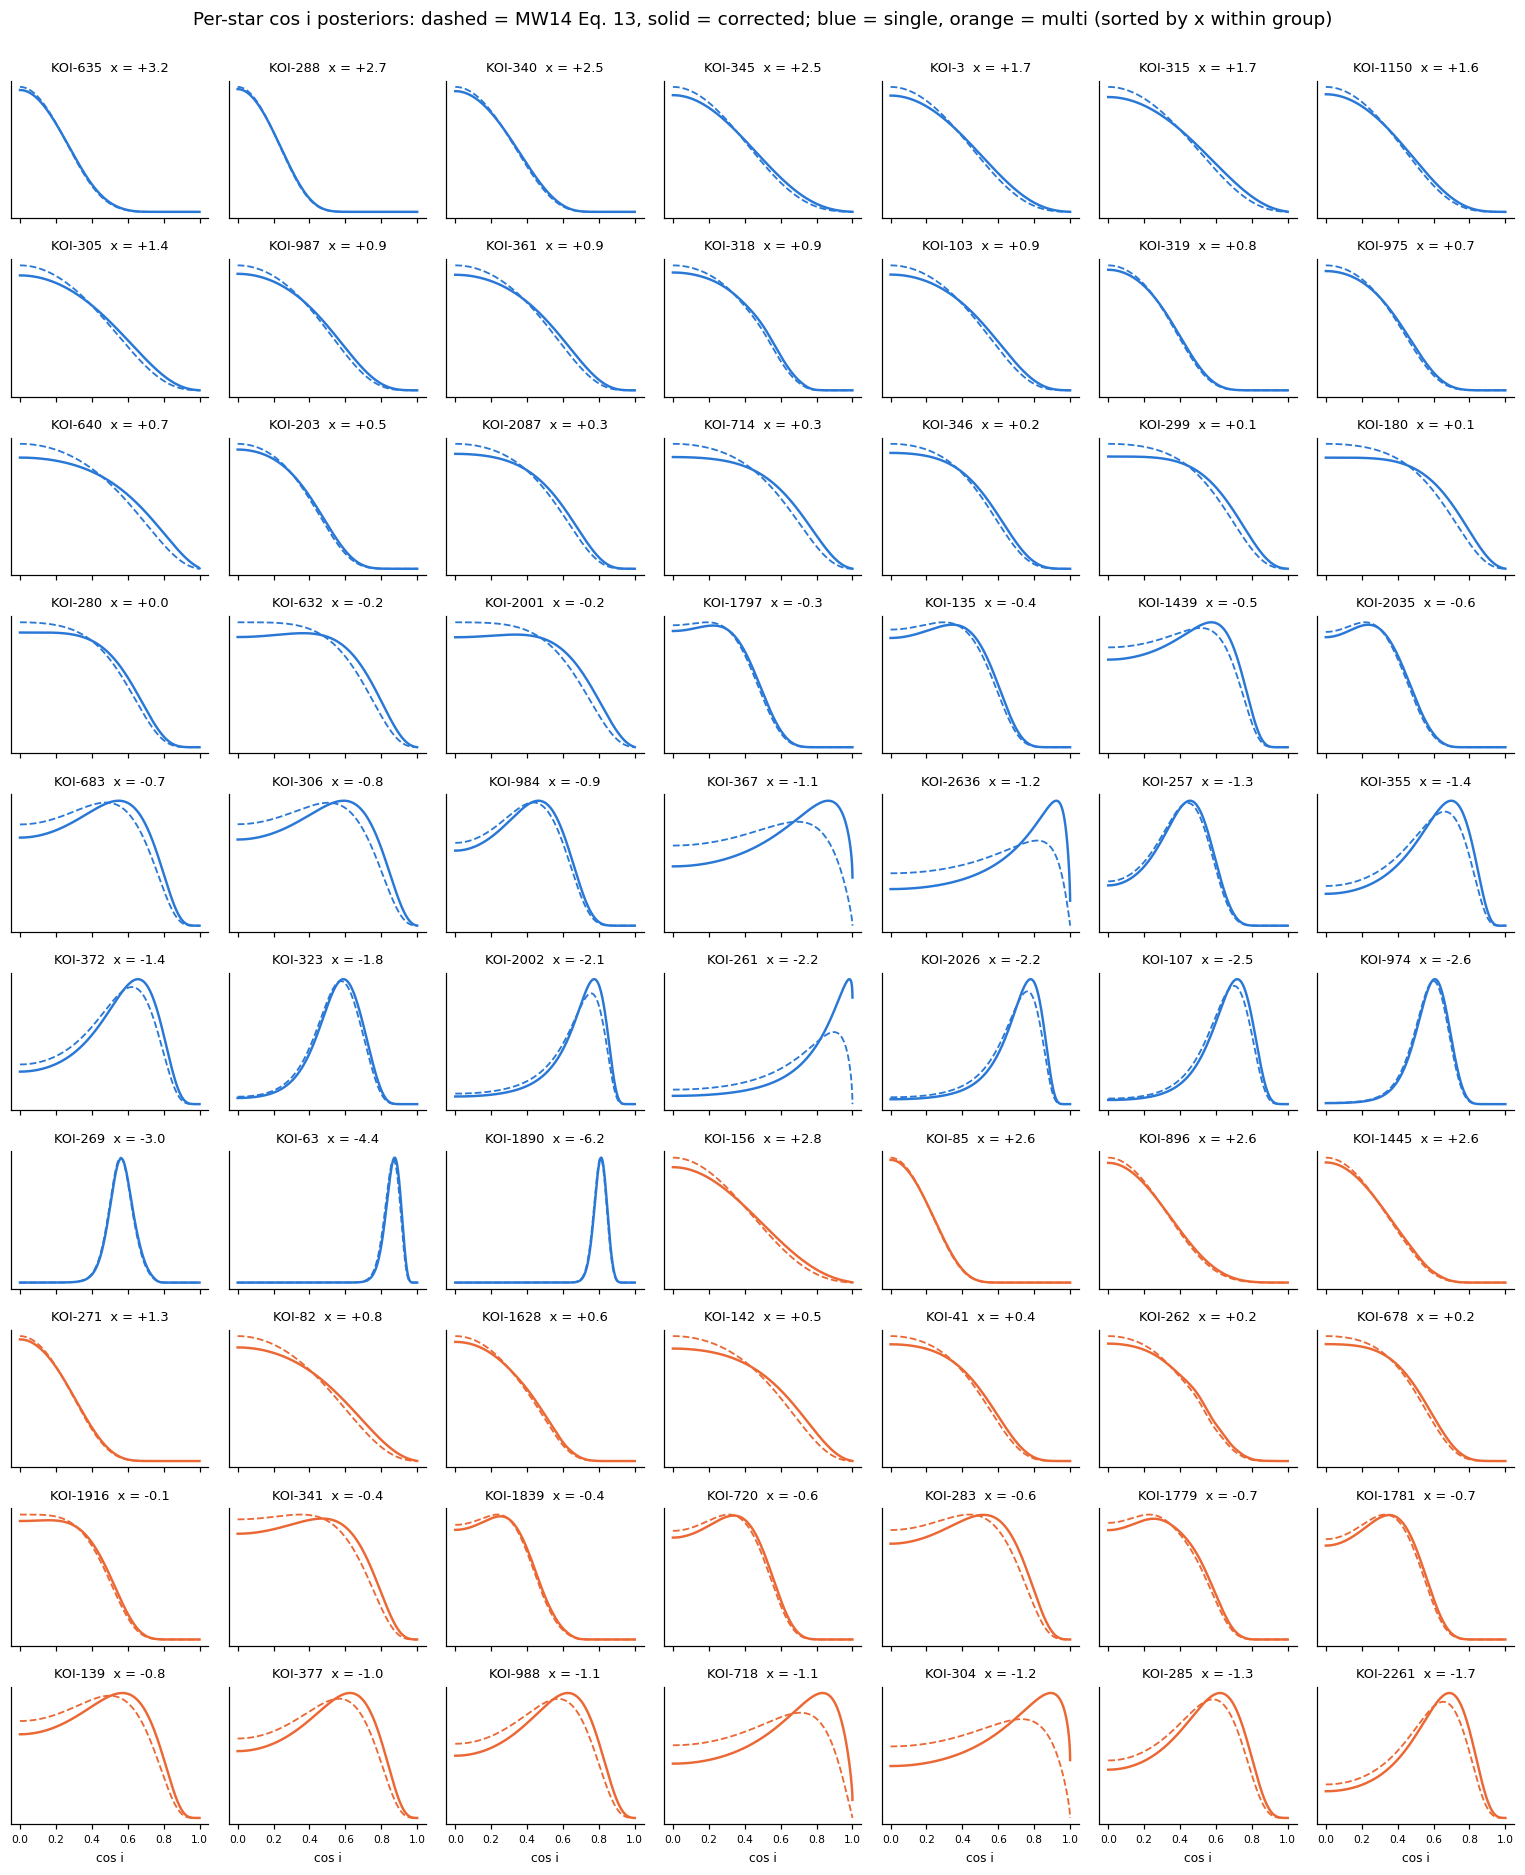

In [3]:
post_m, post_c = runs[("mw14", 1.0)]["post"], runs[("correct", 1.0)]["post"]
order = df.assign(x=x).sort_values(["group", "x"], ascending=[False, False])
fig, axes = plt.subplots(10, 7, figsize=(14, 17), sharex=True)
for ax, (_, r) in zip(axes.flat, order.iterrows()):
    k, c = int(r.koi), GCOL[r.group]
    ax.plot(COSI_GRID, post_m[k], "--", color=c, lw=1.2)
    ax.plot(COSI_GRID, post_c[k], "-", color=c, lw=1.6)
    ax.set_title(f"KOI-{k}  x = {r.x:+.1f}", fontsize=8.5)
    ax.set_yticks([]); ax.tick_params(labelsize=7)
for ax in axes[-1]:
    ax.set_xlabel("cos i", fontsize=8)
fig.suptitle("Per-star cos i posteriors: dashed = MW14 Eq. 13, solid = corrected; "
             "blue = single, orange = multi (sorted by x within group)", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "stage2_per_star_posteriors.png", bbox_inches="tight", dpi=90)

## 3. κ posteriors under both methods (the main figure)

Left: linear κ, where the singles live. Right: log κ, to show the multis'
prior-dominated tail (the prior (1+κ²)^(−3/4) is drawn in gray).

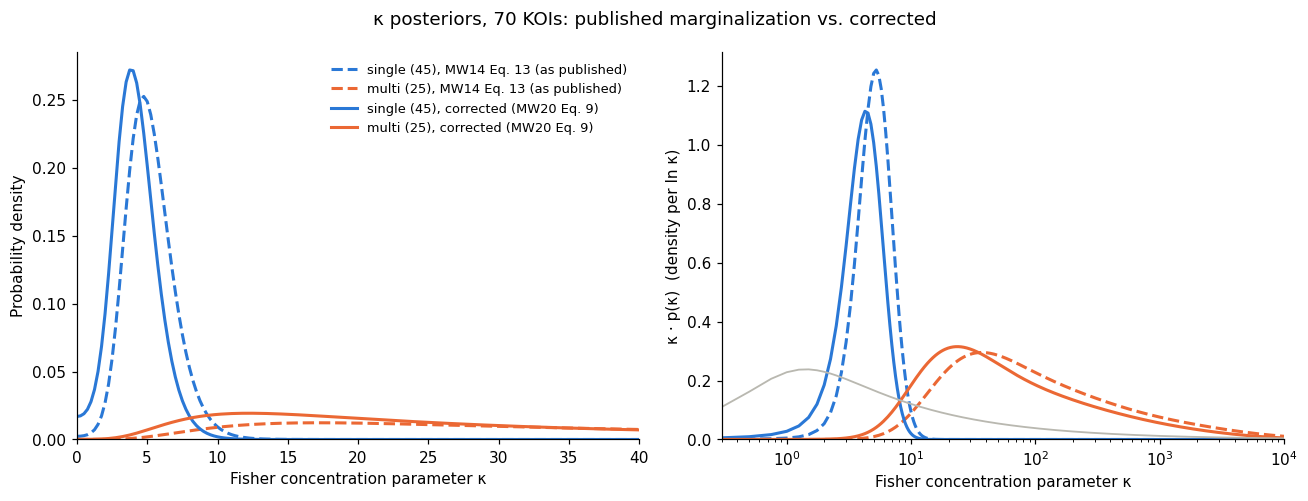

In [4]:
kpost = {(m, g): kappa_posterior(runs[(m, 1.0)]["ll_star"][groups[g]].sum(0)) for m in METHODS for g in groups}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, xscale in zip(axes, ("linear", "log")):
    for (m, g), p in kpost.items():
        ax.plot(KAPPA_GRID, p * (KAPPA_GRID if xscale == "log" else 1), MLS[m], color=GCOL[g], lw=2,
                label=f"{g} ({groups[g].sum()}), {MLABEL[m]}")
    if xscale == "log":
        prior = np.exp(log_kappa_prior(KAPPA_GRID)); prior /= np.trapz(prior, KAPPA_GRID)
        ax.plot(KAPPA_GRID, prior * KAPPA_GRID, color="#b9b8b0", lw=1.2, label="prior")
        ax.set(xscale="log", xlim=(0.3, 1e4), ylabel="κ · p(κ)  (density per ln κ)")
    else:
        ax.set(xlim=(0, 40), ylabel="Probability density")
    ax.set(xlabel="Fisher concentration parameter κ", ylim=(0, None))
axes[0].legend(frameon=False, fontsize=8.5)
fig.suptitle("κ posteriors, 70 KOIs: published marginalization vs. corrected")
fig.tight_layout(); fig.savefig(FIG / "stage2_kappa_posteriors.png", bbox_inches="tight")

## 4. κ summaries and significance: both methods, error-inflation ladder, and the 62-star cut

In [5]:
def summary_row(run, method, label, sel=None, perm_seed=4300):
    sel = np.ones(len(df), bool) if sel is None else sel
    ll, llf = run["ll_star"][sel], per_star_log_likelihood(run["samples"][sel], table_fine)
    row = {"method": method, "sample": label}
    for g in ("single", "multi"):
        m = groups[g][sel]
        s = summarize_kappa(kappa_posterior(ll[m].sum(0)))
        row[f"κ_{g} mode"] = KAPPA_FINE[np.argmax(llf[m].sum(0) + log_kappa_prior(KAPPA_FINE))]
        row[f"κ_{g} 68% HPD"] = f"{s['hpd68_lo']:.1f}–{s['hpd68_hi']:.1f}"
        row[f"κ_{g} median"] = s["median"]
    obs, _, pv = permutation_test(ll, int(groups["single"][sel].sum()), 1000,
                                  np.random.default_rng(perm_seed), groups["single"][sel])
    row.update({"TVD": obs[0], "H²": obs[1], "p(TVD)": pv[0], "p(H²)": pv[1]})
    return row

keep = x <= 2
rows = []
for m in METHODS:
    for f in LADDER:
        rows.append(summary_row(runs[(m, f)], m, f"70 stars, f = {f}"))
    rows.append(summary_row(runs[(m, 1.0)], m, f"62 stars x ≤ +2σ (signal-suppressing), f = 1", keep, 4301))
summary = pd.DataFrame(rows)
summary.to_csv(PROC / "stage2_kappa_summary.csv", index=False)
summary.round(3)

,method,sample,κ_single mode,κ_single 68% HPD,κ_single median,κ_multi mode,κ_multi 68% HPD,κ_multi median,TVD,H²,p(TVD),p(H²)
0,mw14,"70 stars, f = 1.0",4.73,3.3–6.5,5.037,17.20,4.3–160.5,70.961,0.251,0.852,0.017,0.035
1,mw14,"70 stars, f = 1.15",4.82,3.4–6.7,5.147,17.95,4.4–162.7,73.225,0.242,0.851,0.014,0.035
2,mw14,"70 stars, f = 1.35",4.91,3.4–6.8,5.267,18.35,4.5–162.9,74.454,0.232,0.845,0.013,0.037
3,mw14,"62 stars x ≤ +2σ (signal-suppressing), f = 1",4.07,2.7–5.8,4.290,10.85,2.4–88.2,38.010,0.254,0.736,0.052,0.049
4,correct,"70 stars, f = 1.0",3.86,2.5–5.5,4.055,12.25,3.1–98.7,44.281,0.269,0.802,0.030,0.032
5,correct,"70 stars, f = 1.15",3.86,2.5–5.5,4.063,12.65,3.1–102.2,46.416,0.260,0.803,0.031,0.030
6,correct,"70 stars, f = 1.35",3.82,2.4–5.6,4.023,12.80,3.1–103.0,47.368,0.251,0.799,0.036,0.029
7,correct,"62 stars x ≤ +2σ (signal-suppressing), f = 1",3.18,1.7–4.8,3.245,7.78,1.5–42.4,20.618,0.253,0.648,0.181,0.065


Published (MW14 method, 70 stars): κ_single 4.8 (+2.0/−1.6), κ_multi 19.1 (+73.4/−12.1),
p = 0.015 (TVD), 0.036 (H²). The 62-star rows are not interpreted (see the Stage 1 notebook, §13).

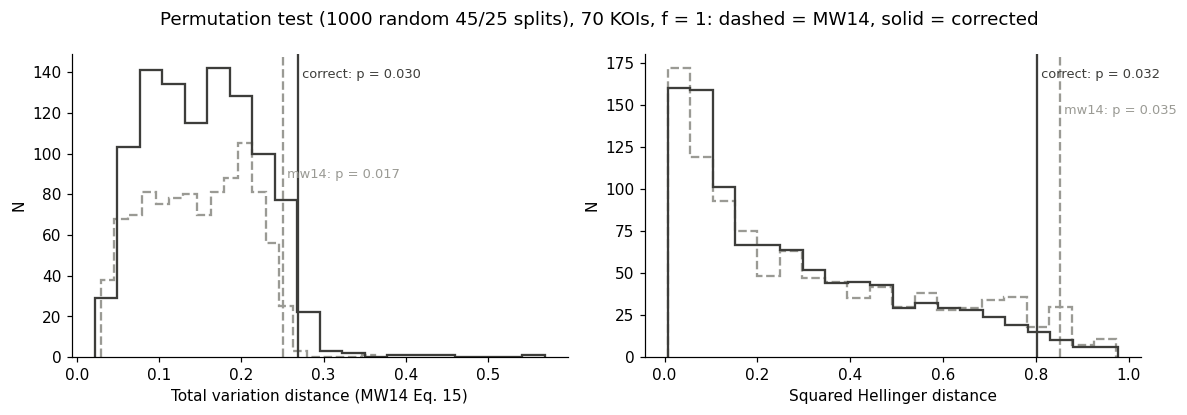

In [6]:
obs_c, trials_c, p_c = permutation_test(runs[("correct", 1.0)]["ll_star"], 45, 1000,
                                         np.random.default_rng(4300), groups["single"])
obs_m, trials_m, p_m = permutation_test(runs[("mw14", 1.0)]["ll_star"], 45, 1000,
                                         np.random.default_rng(4300), groups["single"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, j, name in [(axes[0], 0, "Total variation distance (MW14 Eq. 15)"), (axes[1], 1, "Squared Hellinger distance")]:
    for (o, t, p), m in [((obs_m, trials_m, p_m), "mw14"), ((obs_c, trials_c, p_c), "correct")]:
        col = "#9a9a94" if m == "mw14" else "#3d3d3a"
        ax.hist(t[:, j], bins=20, histtype="step", lw=1.5, color=col, ls=MLS[m])
        ax.axvline(o[j], color=col, ls=MLS[m], lw=1.5)
        ax.text(o[j], ax.get_ylim()[1] * (0.92 if m == "correct" else 0.8),
                f" {m}: p = {p[j]:.3f}", color=col, fontsize=8.5)
    ax.set(xlabel=name, ylabel="N")
fig.suptitle("Permutation test (1000 random 45/25 splits), 70 KOIs, f = 1: dashed = MW14, solid = corrected")
fig.tight_layout(); fig.savefig(FIG / "stage2_permutation_test.png", bbox_inches="tight")

## 5. Shift in the 95% upper limit on i, per star (f = 1)

        count  mean   std   min   25%   50%   75%   max
group                                                  
multi    25.0 -0.31  0.37 -1.23 -0.40 -0.11 -0.08 -0.01
single   45.0 -0.62  1.06 -4.77 -0.45 -0.21 -0.10 -0.01


,koi,group,x,ul95_mw14,ul95_correct,shift_deg
14,261,single,-2.20,83.29,78.52,-4.77
65,2026,single,-2.24,76.67,72.74,-3.93
64,2002,single,-2.13,80.34,77.21,-3.13
6,107,single,-2.47,74.58,71.74,-2.84
69,2636,single,-1.16,86.49,84.98,-1.51
29,323,single,-1.83,77.63,76.14,-1.49
68,2261,multi,-1.69,84.94,83.71,-1.23
23,304,multi,-1.22,86.77,85.55,-1.22
45,718,multi,-1.14,86.75,85.66,-1.09
36,367,single,-1.11,86.91,85.83,-1.08


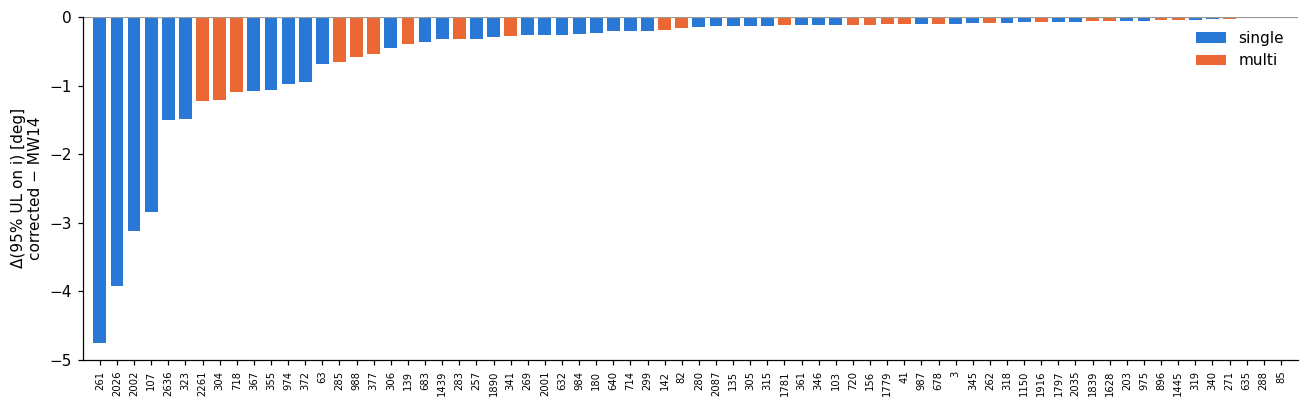

In [7]:
ul = pd.DataFrame({"koi": df.koi, "group": df.group, "x": x,
                   "ul95_mw14": [inclination_upper_limit_deg(COSI_GRID, post_m[int(k)]) for k in df.koi],
                   "ul95_correct": [inclination_upper_limit_deg(COSI_GRID, post_c[int(k)]) for k in df.koi]})
ul["shift_deg"] = ul.ul95_correct - ul.ul95_mw14
ul.to_csv(PROC / "stage2_upper_limit_shifts.csv", index=False)
s = ul.sort_values("shift_deg")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(np.arange(70), s.shift_deg, color=[GCOL[g] for g in s.group], width=0.75)
ax.set_xticks(np.arange(70)); ax.set_xticklabels(s.koi, rotation=90, fontsize=6.5)
ax.axhline(0, color="#9a9a94", lw=0.8)
ax.set(ylabel="Δ(95% UL on i) [deg]\ncorrected − MW14", xlim=(-1, 70))
for g in GCOL:
    ax.bar([np.nan], [np.nan], color=GCOL[g], label=g)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "stage2_upper_limit_shifts.png", bbox_inches="tight")
print(ul.groupby("group").shift_deg.describe().round(2).to_string())
ul.sort_values("shift_deg").head(10).round(2)

## 6. Which stars move? Per-star KL divergence vs. x

KL(p_correct ‖ p_mw14) on the cos i grid, f = 1. Prediction under test: stars
with large x move most.

Pearson r = -0.235 (p = 5.0e-02);  Spearman ρ = -0.527 (p = 2.8e-06)


,koi,group,x,ul95_mw14,ul95_correct,shift_deg,KL
14,261,single,-2.201,83.288,78.523,-4.766,0.398
23,304,multi,-1.216,86.770,85.554,-1.216,0.135
36,367,single,-1.106,86.910,85.830,-1.080,0.114
69,2636,single,-1.157,86.490,84.983,-1.507,0.112
45,718,multi,-1.136,86.752,85.658,-1.094,0.074
65,2026,single,-2.240,76.670,72.739,-3.930,0.018
64,2002,single,-2.134,80.339,77.210,-3.130,0.017
68,2261,multi,-1.693,84.941,83.708,-1.233,0.017


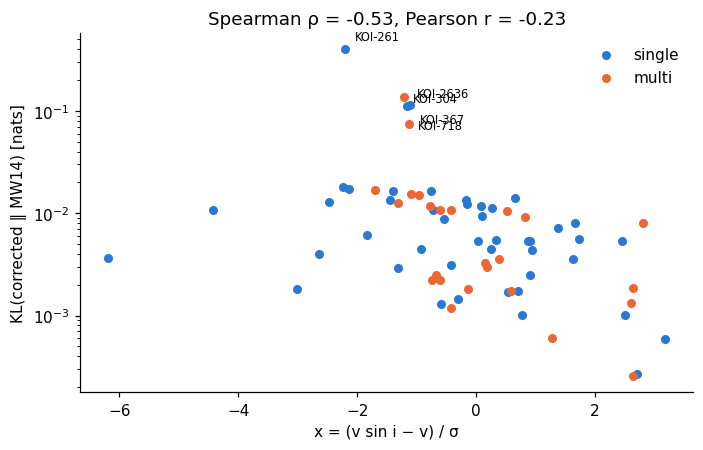

In [8]:
ul["KL"] = [kl_divergence(post_c[int(k)], post_m[int(k)]) for k in df.koi]
pear = st.pearsonr(ul.x, ul.KL); spear = st.spearmanr(ul.x, ul.KL)
print(f"Pearson r = {pear.statistic:+.3f} (p = {pear.pvalue:.1e});  Spearman ρ = {spear.statistic:+.3f} (p = {spear.pvalue:.1e})")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for g in GCOL:
    s = ul[ul.group == g]
    ax.scatter(s.x, s.KL, s=24, color=GCOL[g], label=g, zorder=3)
for j, (_, r) in enumerate(ul.nlargest(5, "KL").iterrows()):
    ax.annotate(f"KOI-{int(r.koi)}", (r.x, r.KL), xytext=(6, 6 - 9 * (j % 3)),
                textcoords="offset points", fontsize=7.5)
ax.set(xlabel="x = (v sin i − v) / σ", ylabel="KL(corrected ‖ MW14) [nats]", yscale="log",
       title=f"Spearman ρ = {spear.statistic:+.2f}, Pearson r = {pear.statistic:+.2f}")
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(FIG / "stage2_kl_vs_x.png", bbox_inches="tight")
ul.sort_values("KL", ascending=False).head(8).round(3)

## Findings (70 stars, f = 1 unless stated)

* **The difference survives the correction.** Corrected: κ_single 3.86
  (68% HPD 2.5–5.5), κ_multi 12.3 (3.1–98.7); permutation p = 0.030 (TVD),
  0.032 (H²), against 0.017 and 0.035 with the published marginalization.
* **Both κ move down.** Restoring the 1/sin i Jacobian removes MW14's
  built-in preference for small cos i, so both populations look less aligned;
  the shift is similar in both, and the separation between them is preserved.
* **Stable under error inflation.** For f = 1.15 and 1.35, p(TVD) = 0.031–0.036
  and p(H²) = 0.029–0.030 under the corrected method.
* **Upper limits only move down**, by up to 4.8° (KOI-261); every star's
  95% limit on i is lower with the corrected method.
* **The "large x moves most" prediction is falsified.** KL(corrected ‖ MW14)
  anti-correlates with x (Spearman ρ = −0.53, p = 3 × 10⁻⁶). The stars that move
  have broad posteriors with mass at intermediate-to-large cos i (moderately
  negative x), where the 1/sin i reweighting matters; stars at x > 0 have
  posteriors piled at cos i ≈ 0, where sin i ≈ 1 and the two methods agree.